# Basic Instruments and Payoffs

In derivatives, a *payoff* is a deterministic function of the terminal underlying price $S_T$.
At this stage, payoffs are defined **independently of any probabilistic model or pricing measure**.
They describe the cash flow of the contract at maturity, not its present value.

Throughout this project, payoffs are treated as functions
$$
\pi : S_T \mapsto \mathbb{R},
$$
and pricing methods introduced later (trees, Black–Scholes–Merton, Monte Carlo) will differ
in how the expectation of these payoffs is computed under a risk-neutral measure.

We denote the payoff of a derivative at maturity by $\pi(S_T)$, 
where $S_T$ is the underlying price at time $T$. 
This notation is standard in the academic derivatives literature, 
where the payoff is treated as a function of the terminal state of the underlying asset 
(e.g. Björk, Duffie, Shreve).

### Notebook Scope

Throughout this notebook, we focus exclusively on payoffs at maturity, defined as functions of the terminal price $S_T$. Valuation and present value are intentionally deferred to later chapters, this alow us to study payoff structures independently of any pricing model.

### Basic derivative payoffs

**Forward contract**

The terminal payoff of a forward contract with delivery price $K$ is linear in the terminal price:
$$
\pi_{\text{fwd}}(S_T; K) = S_T - K
$$

Unlike options, forward payoffs are unbounded both above and below and can take negative values.

---

**European call option**

A European call option gives the right, but not the obligation, to buy the underlying at price $K$ at maturity.
Its payoff is:
$$
\pi_{\text{call}}(S_T; K) = \max(S_T - K, 0)
$$

The call payoff is non-negative and convex in $S_T$.

---

**European put option**

A European put option gives the right, but not the obligation, to sell the underlying at price $K$ at maturity.
Its payoff is:
$$
\pi_{\text{put}}(S_T; K) = \max(K - S_T, 0)
$$

Like the call, the put payoff is non-negative and convex, but it benefits from decreases in $S_T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dv.payoffs import payoff_forward
from dv.payoffs import payoff_call
from dv.payoffs import payoff_put

In [2]:
ST = [80, 90, 100, 110, 120] # Simple example -> Just 5 spot prices
K = 100 # Strike/Delivery Price

pay_for = payoff_forward(ST, K)
pay_for # Array with the forward payoff for each of the inputs

array([-20., -10.,   0.,  10.,  20.])

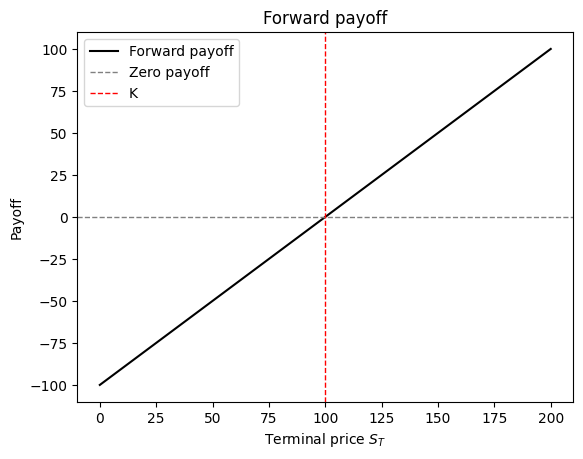

In [3]:
# Visual Test to corroborate the financial intuition

ST = np.linspace(0, 200, 500) # Numpy array with 500 values equally spaced from 0 to 200 (inclusive)
pay_for = payoff_forward(ST, 100) # Same payoff function but with the 500 values array as an input

plt.figure()

plt.plot(ST, pay_for, color="black", label="Forward payoff")
plt.axhline(0, color="gray", linestyle="--", linewidth=1, label="Zero payoff")
plt.axvline(100, color="red", linestyle="--", linewidth=1, label="K")

plt.title("Forward payoff")
plt.xlabel("Terminal price $S_T$")
plt.ylabel("Payoff")
plt.legend()
plt.show()

In [4]:
ST = [80, 90, 100, 110, 120] # Simple example -> Just 5 spot prices
K = 100 # Strike Price

pay_call = payoff_call(ST, K)
pay_call # Array with the European call payoff for each of the inputs

array([ 0.,  0.,  0., 10., 20.])

In [5]:
ST = [80, 90, 100, 110, 120] # Simple example -> Just 5 spot prices
K = 100 # Strike Price

pay_put = payoff_put(ST, K)
pay_put # Array with the European put payoff for each of the inputs

array([20., 10.,  0.,  0.,  0.])

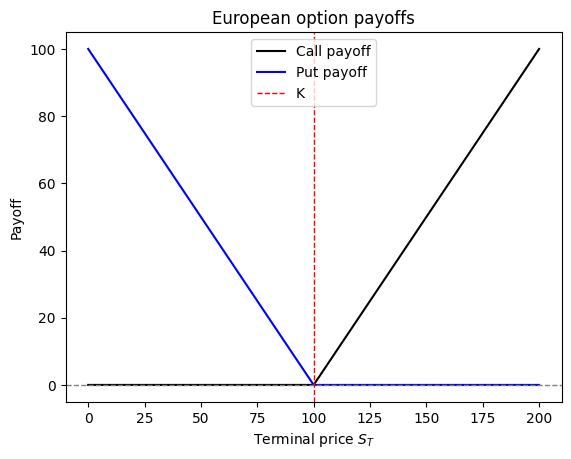

In [6]:
# Visual Test to corroborate the financial intuition

ST = np.linspace(0, 200, 500) # Numpy array with 500 values equally spaced from 0 to 200 (inclusive)
pay_call = payoff_call(ST, 100) # Same payoff function but with the 500 values array as an input
pay_put = payoff_put(ST, 100) # Same payoff function but with the 500 values array as an input

plt.figure()
plt.plot(ST, pay_call, color="black", label="Call payoff")
plt.plot(ST, pay_put, color="blue", label="Put payoff")
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(K, color="red", linestyle="--", linewidth=1, label="K")
plt.title("European option payoffs")
plt.xlabel("Terminal price $S_T$")
plt.ylabel("Payoff")
plt.legend()
plt.show()